# Week 8 Demo Overview
## Paradigm 3 – Encoder-Decoders: Unified Architectures
This notebook demonstrates the core concepts of BART and T5, focusing on corruption strategies, unified text-to-text frameworks, attention mechanisms, and the differences between extractive and generative QA.

In [18]:
# !pip install -q transformers sentencepiece torch matplotlib
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import T5Tokenizer, T5ForConditionalGeneration, BertTokenizer, BertForQuestionAnswering

# Note: We avoid 'mps' (Mac GPU) here because T5's model.generate() is known to hang indefinitely on MPS due to PyTorch bugs.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## Demo 1: Corruption Visualization — BART vs. T5

In [19]:
def bart_text_infilling(tokens, num_spans=2, lam=3):
    """
    Simulates BART's text infilling strategy with <s> and </s>.
    """
    import random
    corrupted = tokens.copy()
    for _ in range(num_spans):
        span_len = np.random.poisson(lam)
        start_idx = random.randint(0, max(0, len(corrupted) - span_len))
        # A 0-length span does NOT mean "skip": per Lewis et al. it INSERTS a [MASK]
        # that stands for nothing, forcing the model to learn to delete it again.
        corrupted = corrupted[:start_idx] + ['[MASK]'] + corrupted[start_idx+span_len:]
    
    # Real BART wraps BOTH the encoder input and the target with <s> (BOS) and </s> (EOS).
    # We show them on both sides so the length comparison against T5 is apples-to-apples.
    corrupted = ['<s>'] + corrupted + ['</s>']
    target    = ['<s>'] + tokens    + ['</s>']
    
    print(f'BART Corrupted Input Length (src_len): {len(corrupted)}')
    print(f'BART Target Length (tgt_len): {len(target)}')
    print(f"Corrupted Input: {' '.join(corrupted)}")
    print(f"Target Output: {' '.join(target)}")
    return corrupted, target

In [20]:
def t5_span_corruption(tokens, num_spans=2, span_len=3):
    """
    Simulates T5's span corruption strategy.

    Note: we use a FIXED span_len here so the printout is easy to follow in class.
    Real T5 draws each span length from Poisson(lambda=3), like BART's text infilling.
    """
    import random
    
    # Pick non-overlapping start indices
    available_indices = list(range(len(tokens) - span_len + 1))
    selected_starts = []
    for _ in range(num_spans):
        if not available_indices:
            break
        start = random.choice(available_indices)
        selected_starts.append(start)
        # Remove indices that would overlap OR sit directly adjacent to this span.
        # Real T5 span corruption never emits two sentinels side by side: spans are always
        # separated by at least one kept token.
        available_indices = [i for i in available_indices if i < start - span_len or i > start + span_len]
        
    selected_starts.sort()
    
    corrupted = []
    target = []
    curr_idx = 0
    
    for i, start_idx in enumerate(selected_starts):
        sentinel = f'<extra_id_{i}>'
        span = tokens[start_idx : start_idx + span_len]
        
        corrupted.extend(tokens[curr_idx : start_idx])
        corrupted.append(sentinel)
        
        target.extend([sentinel] + span)
        curr_idx = start_idx + span_len
        
    corrupted.extend(tokens[curr_idx:])
    target.append(f'<extra_id_{len(selected_starts)}>')

    # Real T5 ends BOTH the encoder input and the target with </s>.
    # Note the final <extra_id_N> is NOT the EOS — it means "no more missing spans",
    # and the actual </s> follows it. Check with: T5Tokenizer(...).input_ids[-1] == 1
    corrupted.append('</s>')
    target.append('</s>')
    
    print(f'T5 Corrupted Input Length (src_len): {len(corrupted)}')
    print(f'T5 Target Length (tgt_len): {len(target)}')
    print(f'Corrupted Input: {" ".join(corrupted)}')
    print(f'Target Output: {" ".join(target)}')
    return corrupted, target


In [21]:
# Seeded so the printed example is identical in the handout, on the projector,
# and on every student's machine. Change the seed to see other corruptions.
import random
random.seed(6)
np.random.seed(6)

sentence = "The quick brown fox jumps over the lazy dog and runs away rapidly".split()
print("=== BART Full Reconstruction ===")
bart_src, bart_tgt = bart_text_infilling(sentence.copy(), num_spans=2, lam=3)

print("\n=== T5 Span Corruption ===")
t5_src, t5_tgt = t5_span_corruption(sentence.copy(), num_spans=2, span_len=3)

tgt_ratio = len(bart_tgt) / max(1, len(t5_tgt))
print(f'\nTarget length ratio (BART / T5): {tgt_ratio:.2f}')
print('Both targets are counted the SAME way — special tokens included on both sides')
print('(BART: <s>...</s>  |  T5: ...<extra_id_N> </s>), so the ratio is a fair comparison.')

=== BART Full Reconstruction ===
BART Corrupted Input Length (src_len): 12
BART Target Length (tgt_len): 15
Corrupted Input: <s> The [MASK] fox jumps over the lazy dog [MASK] rapidly </s>
Target Output: <s> The quick brown fox jumps over the lazy dog and runs away rapidly </s>

=== T5 Span Corruption ===
T5 Corrupted Input Length (src_len): 10
T5 Target Length (tgt_len): 10
Corrupted Input: The quick <extra_id_0> over the <extra_id_1> runs away rapidly </s>
Target Output: <extra_id_0> brown fox jumps <extra_id_1> lazy dog and <extra_id_2> </s>

Target length ratio (BART / T5): 1.50
Both targets are counted the SAME way — special tokens included on both sides
(BART: <s>...</s>  |  T5: ...<extra_id_N> </s>), so the ratio is a fair comparison.


**Compute Efficiency Implications:**
Notice that T5's target sequence is much shorter than BART's. Since decoder self-attention computational cost is quadratic with respect to the target length ($O(N^2)$), a significantly shorter target means the decoder operates much faster during pre-training.

## Demo 2: T5 Text-to-Text — One Model, Many Tasks

In [22]:
# Load T5-small model and tokenizer
t5_tokenizer = T5Tokenizer.from_pretrained('t5-small', legacy=False)
t5_model = T5ForConditionalGeneration.from_pretrained('t5-small').to(device)
print("T5 Model Loaded")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5 Model Loaded


In [23]:
def generate_t5(prompt):
    inputs = t5_tokenizer(prompt, return_tensors='pt').to(device)
    # Shape: [batch, seq_len]
    with torch.no_grad():
        outputs = t5_model.generate(**inputs, max_length=50)
        # Shape: [batch, tgt_len]
    return t5_tokenizer.decode(outputs[0], skip_special_tokens=True)

print("Translation:", generate_t5("translate English to German: The house is wonderful."))

Translation: Das Haus ist wunderbar.


In [24]:
article = "The Transformer is a deep learning architecture that relies on the attention mechanism. It has been widely used in natural language processing."
print("Summarization:", generate_t5(f"summarize: {article}"))

Summarization: the Transformer is a deep learning architecture that relies on the attention mechanism. it has been widely used in natural language processing.


In [25]:
print("QA:", generate_t5("question: What mechanism does the Transformer rely on? context: The Transformer is a deep learning architecture that relies on the attention mechanism."))

QA: attention


In [26]:
print("Sentiment:", generate_t5("sst2 sentence: I absolutely loved this movie, it was fantastic!"))

Sentiment: positive


**Discussion:** 
We used the exact same model, tokenizer, and decoding procedure for Translation, Summarization, QA, and Sentiment Analysis. The only difference was the task prefix!

### Demo 2c: Interactive T5 Playground
Try feeding your own Text-to-Text prompts into T5! The format is simply `{prefix}: {input_text}`.

*(Note: `t5-small` might make mistakes on complex tasks like the CoLA acceptability judgment due to its tiny size, but the text-to-text format is what matters!)*

In [27]:
# Feel free to change this string and run the cell!
my_prompt = "cola sentence: She go to school yesterday."

print(f"Input  : {my_prompt}")
print(f"Output : {generate_t5(my_prompt)}")

# NOTE: CoLA asks "is this sentence grammatically ACCEPTABLE?" — it is a classification
# task, not a correction task. t5-small answers "acceptable" here, which is WRONG
# ("She go" is ungrammatical); you need t5-base or larger to get it right.
# What matters for this week is the FORMAT (text in -> text out), not the answer.

Input  : cola sentence: She go to school yesterday.
Output : acceptable


## Demo 3: Encoder, Decoder, and Cross-Attention Heatmaps

In [28]:
# T5 Dynamic Translation & Attention Extraction
prompt = "translate English to German: Hello world"
inputs = t5_tokenizer(prompt, return_tensors="pt").to(device)

# 1. Let T5 generate the translation dynamically
with torch.no_grad():
    generated_ids = t5_model.generate(**inputs, max_length=10)

# 2. Extract attention matrices across encoder, decoder, and cross-attention
with torch.no_grad():
    outputs = t5_model(input_ids=inputs.input_ids, decoder_input_ids=generated_ids, output_attentions=True)

enc_attn = outputs.encoder_attentions[-1][0, 0].cpu().numpy()  # [batch, n_heads, src_len, src_len] -> [src_len, src_len]
dec_attn = outputs.decoder_attentions[-1][0, 0].cpu().numpy()  # [tgt_len, tgt_len]
cross_attn = outputs.cross_attentions[-1][0, 0].cpu().numpy()  # [tgt_len, src_len]

print(f"Encoder attention shape: {enc_attn.shape}")
print(f"Decoder attention shape: {dec_attn.shape}")
print(f"Cross attention shape: {cross_attn.shape}")

# Convert token IDs to string tokens for heatmap axis labels
src_tokens = t5_tokenizer.convert_ids_to_tokens(inputs.input_ids[0])
tgt_tokens = t5_tokenizer.convert_ids_to_tokens(generated_ids[0])


Encoder attention shape: (8, 8)
Decoder attention shape: (5, 5)
Cross attention shape: (5, 8)


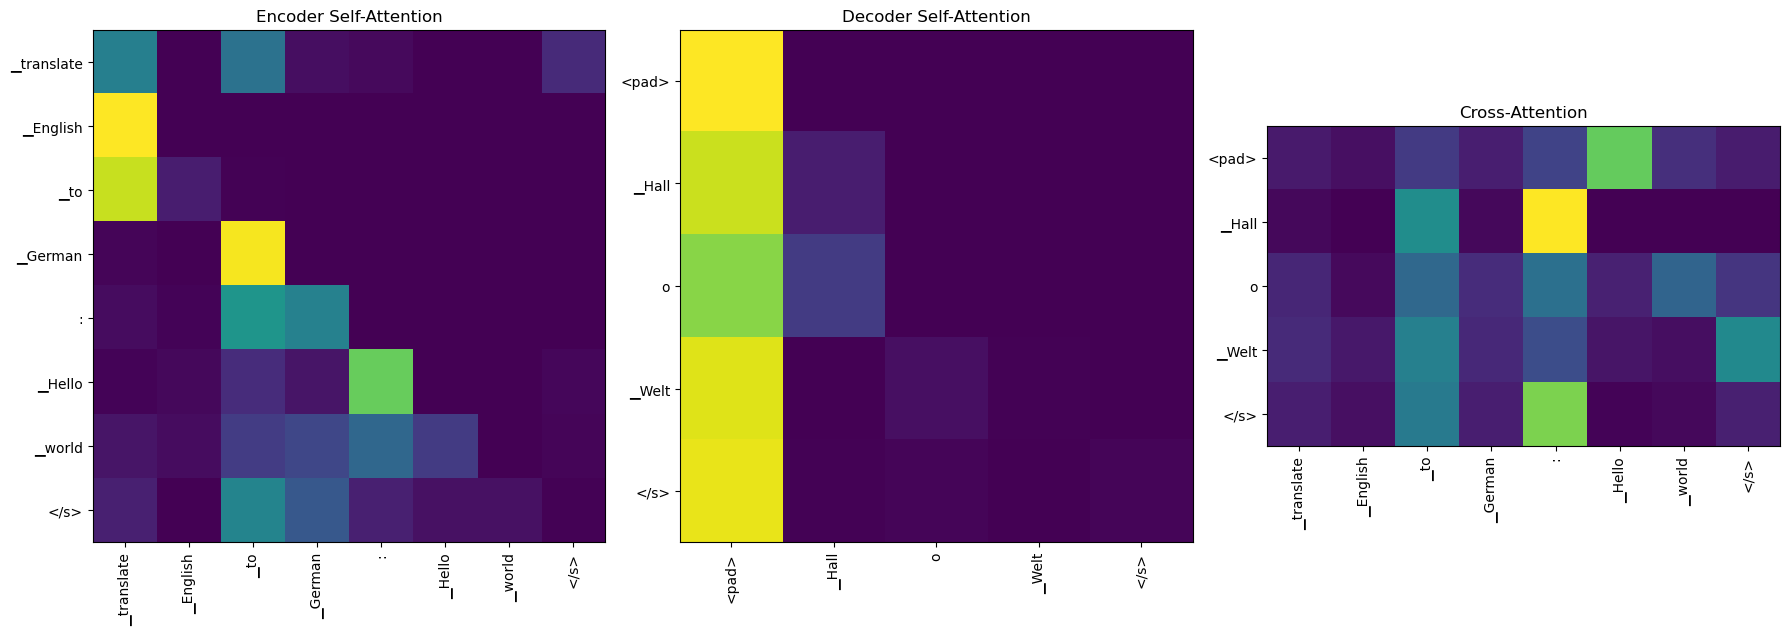

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(enc_attn, cmap='viridis')
axes[0].set_title('Encoder Self-Attention')
axes[0].set_xticks(range(len(src_tokens)))
axes[0].set_yticks(range(len(src_tokens)))
axes[0].set_xticklabels(src_tokens, rotation=90)
axes[0].set_yticklabels(src_tokens)

axes[1].imshow(dec_attn, cmap='viridis')
axes[1].set_title('Decoder Self-Attention')
axes[1].set_xticks(range(len(tgt_tokens)))
axes[1].set_yticks(range(len(tgt_tokens)))
axes[1].set_xticklabels(tgt_tokens, rotation=90)
axes[1].set_yticklabels(tgt_tokens)

axes[2].imshow(cross_attn, cmap='viridis')
axes[2].set_title('Cross-Attention')
axes[2].set_xticks(range(len(src_tokens)))
axes[2].set_yticks(range(len(tgt_tokens)))
axes[2].set_xticklabels(src_tokens, rotation=90)
axes[2].set_yticklabels(tgt_tokens)

plt.tight_layout()
plt.show()


**Interpretation:**
1. **Encoder Self-Attention:** Bidirectional context (full matrix).
2. **Decoder Self-Attention:** Autoregressive, causal context (lower-triangular).
3. **Cross-Attention:** Connects Decoder tokens (rows) to Encoder tokens (columns).

**How to read the heatmaps:**
- **Y-axis (Rows) = Query (Q):** The token that is currently "looking" for information.
- **X-axis (Columns) = Key (K):** The tokens that are being "looked at".
- In Cross-Attention, the Decoder (Y-axis) uses its Queries to look at the Encoder's Keys (X-axis).

## Demo 4: Two Faces of QA — Extractive vs. Generative

In [30]:
# BERT Extractive QA
bert_tokenizer = BertTokenizer.from_pretrained('bert-large-uncased-whole-word-masking-finetuned-squad')
bert_model = BertForQuestionAnswering.from_pretrained('bert-large-uncased-whole-word-masking-finetuned-squad').to(device)

question = "Why was the game canceled?"
context = "Due to the heavy rain that started yesterday, the field was completely flooded. As a result, the referee decided to cancel the game."

inputs = bert_tokenizer(question, context, return_tensors='pt').to(device)  # Shape: [batch, seq_len]
with torch.no_grad():
    outputs = bert_model(**inputs)
    # outputs.start_logits shape: [batch, seq_len]
    # outputs.end_logits shape: [batch, seq_len]
    start_idx = torch.argmax(outputs.start_logits)  # Shape: scalar (argmax over seq_len)
    end_idx = torch.argmax(outputs.end_logits)  # Shape: scalar

print(f"BERT Predicted Start Index: {start_idx.item()}")
print(f"BERT Predicted End Index:   {end_idx.item()}")

# Slice verbatim tokens using the predicted indices
bert_answer = bert_tokenizer.convert_tokens_to_string(bert_tokenizer.convert_ids_to_tokens(inputs.input_ids[0][start_idx:end_idx+1]))
print(f"BERT Extracted Substring:   '{bert_answer}'")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: bert-large-uncased-whole-word-masking-finetuned-squad
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT Predicted Start Index: 11
BERT Predicted End Index:   21
BERT Extracted Substring:   'heavy rain that started yesterday, the field was completely flooded'


In [31]:
# T5 Generative QA
t5_qa_prompt = f"question: {question} context: {context}"
t5_answer = generate_t5(t5_qa_prompt)
print("T5 Generative Answer:", t5_answer)

T5 Generative Answer: heavy rain


In [32]:
print(f"BERT Extractive Answer (Indices [{start_idx.item()}:{end_idx.item()}]): '{bert_answer}' (verbatim substring sliced from context)")
print(f"T5 Generative Answer:                  '{t5_answer}' (generated token-by-token — here it happens to reuse context words)")


print()
print("Is the T5 answer a verbatim substring of the context?",
      t5_answer.lower() in context.lower())
print("--> IMPORTANT: BERT *cannot* leave the context (it slices indices).")
print("    T5 *may* leave it, but is not obliged to — here it stayed inside.")
print("    The difference is the MECHANISM (pointing vs generating), not this one output.")

BERT Extractive Answer (Indices [11:21]): 'heavy rain that started yesterday, the field was completely flooded' (verbatim substring sliced from context)
T5 Generative Answer:                  'heavy rain' (generated token-by-token — here it happens to reuse context words)

Is the T5 answer a verbatim substring of the context? True
--> IMPORTANT: BERT *cannot* leave the context (it slices indices).
    T5 *may* leave it, but is not obliged to — here it stayed inside.
    The difference is the MECHANISM (pointing vs generating), not this one output.


In [33]:
# === Case 2: Zero Context (What happens when there is NO Context?) ===
no_context_question = "What is the capital of Germany?"

# 1. BERT Extractive (Requires context to slice text)
bert_no_ctx_inputs = bert_tokenizer(no_context_question, "", return_tensors="pt").to(device)
with torch.no_grad():
    b_out = bert_model(**bert_no_ctx_inputs)
    s_idx = torch.argmax(b_out.start_logits).item()
    e_idx = torch.argmax(b_out.end_logits).item()
bert_no_ctx_ans = bert_tokenizer.convert_tokens_to_string(
    bert_tokenizer.convert_ids_to_tokens(bert_no_ctx_inputs.input_ids[0][s_idx:e_idx+1])
)

# 2. T5 Generative (Attempts text-to-text generation directly)
t5_no_ctx_ans = generate_t5(f"question: {no_context_question}")

print("=== Case 2: Zero Context (Extractive Failure vs. Generative Output) ===")
print(f"Question: '{no_context_question}'")
print(f"BERT Extractive Output: '{bert_no_ctx_ans}'  <-- Highlights its own question (Fails without context)")
print(f"T5 Generative Output:   '{t5_no_ctx_ans}'  <-- Generates text, but hallucinates (t5-small capacity limit)")


=== Case 2: Zero Context (Extractive Failure vs. Generative Output) ===
Question: 'What is the capital of Germany?'
BERT Extractive Output: 'what is the capital of germany'  <-- Highlights its own question (Fails without context)
T5 Generative Output:   'Germany'  <-- Generates text, but hallucinates (t5-small capacity limit)


**Summary:** 
Extractive QA identifies the start and end positions of the answer within the context.
Generative QA writes the answer out token-by-token instead of pointing at it.

Note the honest caveat: in this example T5's answer (`heavy rain`) *is* a substring of the context, so nothing abstractive happened. The point is the **mechanism** — BERT is structurally incapable of producing a token that is not in the input, while T5 is free to (which is also why T5 can hallucinate).

## Demo 5: BART vs T5 (The Prefix Difference)
Unlike T5's universal text-to-text format, standard BART models are fine-tuned specifically for a single task and **do not** use prefixes. We show this in two steps:

- **Part A — T5 the Generalist:** the same input with and without a task prefix. Without the prefix T5 does *not* fall back to "do nothing" — it performs a completely different task.
- **Part B — BART the Specialist:** a BART model fine-tuned for summarization (`sshleifer/distilbart-cnn-12-6`), which has no prefix concept at all.

In [34]:
from transformers import BartTokenizer, BartForConditionalGeneration

print("Loading BART Summarization Model...")
bart_tokenizer = BartTokenizer.from_pretrained('sshleifer/distilbart-cnn-12-6')
bart_model = BartForConditionalGeneration.from_pretrained('sshleifer/distilbart-cnn-12-6').to(device)

long_text = """The James Webb Space Telescope (JWST) is a space telescope designed primarily to conduct infrared astronomy. As the largest optical telescope in space, its high resolution and sensitivity allow it to view objects too early, distant, or faint for the Hubble Space Telescope. This enables investigations across many fields of astronomy and cosmology."""

# ============ Part A: T5 is a Generalist — the prefix SELECTS the task ============
# The clearest test is sentiment: same sentence, with and without the 'sst2 sentence:' prefix.
sentiment_input = "I absolutely loved this movie, it was fantastic!"

sst2_with    = generate_t5("sst2 sentence: " + sentiment_input)
sst2_without = generate_t5(sentiment_input)

print("\n--- Part A: what the prefix actually does ---")
print(f"A1. WITH    'sst2 sentence:' -> '{sst2_with}'")
print(f"A2. WITHOUT any prefix       -> '{sst2_without}'")
print("    Without a prefix T5 does not 'do nothing' — it falls back to a DIFFERENT task")
print("    (translation, the most common prefix in its multi-task pre-training mix).")
print("    The prefix is not decoration: it is the task switch.\n")

# ============ Part B: T5 vs BART on summarization ============
# 1. T5 WITH Prefix ('summarize: ')
t5_prompt_with = "summarize: " + long_text
t5_inputs_with = t5_tokenizer(t5_prompt_with, return_tensors='pt', max_length=512, truncation=True).to(device)
with torch.no_grad():
    t5_out_with = t5_model.generate(**t5_inputs_with, max_length=80, num_beams=4)
t5_summary_with = t5_tokenizer.decode(t5_out_with[0], skip_special_tokens=True)

# 2. T5 WITHOUT Prefix on the same article
t5_inputs_no = t5_tokenizer(long_text, return_tensors='pt', max_length=512, truncation=True).to(device)
with torch.no_grad():
    t5_out_no = t5_model.generate(**t5_inputs_no, max_length=80, num_beams=4)
t5_summary_no = t5_tokenizer.decode(t5_out_no[0], skip_special_tokens=True)

# 3. BART (Specialist - Requires NO prefix at all)
bart_inputs = bart_tokenizer(long_text, return_tensors='pt', max_length=512, truncation=True).to(device)
with torch.no_grad():
    bart_outputs = bart_model.generate(**bart_inputs, max_length=80, min_length=20, num_beams=4, length_penalty=2.0)
bart_summary = bart_tokenizer.decode(bart_outputs[0], skip_special_tokens=True).strip()

print("--- Part B: Specialist vs Generalist on summarization ---")
print(f"1. T5 Summary (WITH 'summarize:' prefix) :\n   '{t5_summary_with}'\n")
print(f"2. T5 Output (WITHOUT prefix)                  :\n   '{t5_summary_no}'\n")
print("   ^ On this article the no-prefix output still looks summary-ish, because raw C4-style")
print("     text is close to T5's pre-training distribution. That is exactly why Part A used")
print("     sentiment: there the missing prefix is unmistakably fatal.\n")
print(f"3. BART Summary (Specialist - No prefix needed):\n   '{bart_summary}'\n")


Loading BART Summarization Model...


Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]


--- Part A: what the prefix actually does ---
A1. WITH    'sst2 sentence:' -> 'positive'
A2. WITHOUT any prefix       -> 'Ich habe voll lieb diese Film, es war fantas fantas!'
    Without a prefix T5 does not 'do nothing' — it falls back to a DIFFERENT task
    (translation, the most common prefix in its multi-task pre-training mix).
    The prefix is not decoration: it is the task switch.

--- Part B: Specialist vs Generalist on summarization ---
1. T5 Summary (WITH 'summarize:' prefix) :
   'the James Webb Space Telescope (JWST) is a space telescope designed primarily to conduct infrared astronomy. its high resolution and sensitivity allow it to view objects too early, distant, or faint for the Hubble Space Telescope.'

2. T5 Output (WITHOUT prefix)                  :
   '(JWST) is a space telescope designed primarily to conduct infrared astronomy.'

   ^ On this article the no-prefix output still looks summary-ish, because raw C4-style
     text is close to T5's pre-training distri